# Regresión regularizada: Ridge y Lasso
**Sobreajuste · penalización L2 y L1 · elección de alpha con validación cruzada**

Retomamos el consumo de autos (Auto MPG) de la clase anterior. Esta vez le damos al modelo **muchas variables**
para provocar sobreajuste, y vemos cómo Ridge y Lasso lo controlan penalizando los coeficientes.

Notebook expositiva: ejecutar en orden con **Shift + Enter** en Google Colab.
Fijamos la versión de scikit-learn para reproducir el ejemplo.
Se necesita conexión a internet para descargar los datos; no hace falta una GPU.

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 1. Los datos

Misma preparación que en la notebook N04: descartamos los autos sin potencia, pasamos `origin` a dummies
y reservamos **20 % para prueba**.

In [2]:
autos = sns.load_dataset("mpg").dropna()
datos = pd.get_dummies(autos.drop(columns="name"), columns=["origin"], drop_first=True, dtype=int)
X = datos.drop(columns="mpg")
y = datos["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Entrenamiento:", X_train.shape, "· Prueba:", X_test.shape)

Entrenamiento: (313, 8) · Prueba: (79, 8)


## 2. Provocar el sobreajuste: muchas variables

`PolynomialFeatures(degree=3)` agrega los cuadrados, cubos y productos entre variables (peso², peso · potencia, ...).
Pasamos de 8 a **164 variables** para solo 313 autos de entrenamiento: el escenario donde la regresión lineal sufre.

Usamos `make_pipeline` para que las transformaciones se ajusten solo con entrenamiento.

In [3]:
def evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    return {"Modelo": nombre,
            "R² entrenamiento": r2_score(y_train, modelo.predict(X_train)),
            "R² prueba": r2_score(y_test, modelo.predict(X_test)),
            "MAE prueba": mean_absolute_error(y_test, modelo.predict(X_test))}

lineal = make_pipeline(StandardScaler(), LinearRegression())
lineal_poli = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), LinearRegression())

resultados = [evaluar("Lineal (8 variables)", lineal),
              evaluar("Lineal polinómica (164 variables)", lineal_poli)]
display(pd.DataFrame(resultados).round(3))

,Modelo,R² entrenamiento,R² prueba,MAE prueba
0,Lineal (8 variables),0.829,0.792,2.462
1,Lineal polinómica (164 variables),0.959,-17969.689,173.160


**Lectura:** con 164 variables, el modelo se ajusta mejor al entrenamiento pero **empeora en prueba**: memorizó ruido.
Los coeficientes también lo delatan: son enormes y se compensan entre sí.

In [4]:
coefs = lineal_poli[-1].coef_
print(f"Coeficiente más grande en valor absoluto: {np.abs(coefs).max():,.0f}")

Coeficiente más grande en valor absoluto: 81,340


## 3. Ridge: penalizar el cuadrado de los coeficientes (L2)

Ridge minimiza **error cuadrático + alpha · Σ β²**. Cuanto mayor es `alpha`, más se encogen los coeficientes.
La penalización depende de la escala de cada variable, por eso **escalamos antes** (`StandardScaler`).

In [5]:
ridge = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), Ridge(alpha=10))
resultados.append(evaluar("Ridge, alpha = 10", ridge))
display(pd.DataFrame(resultados).round(3))
print(f"Coeficiente más grande con Ridge: {np.abs(ridge[-1].coef_).max():.2f}")

,Modelo,R² entrenamiento,R² prueba,MAE prueba
0,Lineal (8 variables),0.829,0.792,2.462
1,Lineal polinómica (164 variables),0.959,-17969.689,173.160
2,"Ridge, alpha = 10",0.891,0.854,2.015


Coeficiente más grande con Ridge: 1.39


## 4. Lasso: penalizar el valor absoluto (L1)

Lasso minimiza **error cuadrático + alpha · Σ |β|**. Además de encoger, lleva muchos coeficientes
**exactamente a cero**: elige variables.

In [6]:
lasso = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), Lasso(alpha=0.05, max_iter=50000))
resultados.append(evaluar("Lasso, alpha = 0.05", lasso))
display(pd.DataFrame(resultados).round(3))
print("Coeficientes distintos de cero con Lasso:", np.sum(lasso[-1].coef_ != 0), "de", lasso[-1].coef_.size)

,Modelo,R² entrenamiento,R² prueba,MAE prueba
0,Lineal (8 variables),0.829,0.792,2.462
1,Lineal polinómica (164 variables),0.959,-17969.689,173.160
2,"Ridge, alpha = 10",0.891,0.854,2.015
3,"Lasso, alpha = 0.05",0.882,0.859,1.981


Coeficientes distintos de cero con Lasso: 13 de 164


## 5. El efecto de alpha

Recorremos valores de alpha en escala logarítmica y miramos el R² en entrenamiento y en prueba.
Con alpha muy chico volvemos al sobreajuste; con alpha muy grande el modelo queda demasiado simple (subajuste).

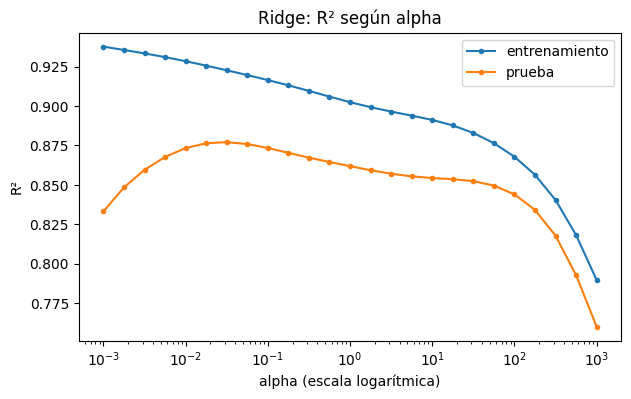

In [7]:
alphas = np.logspace(-3, 3, 25)
filas = []
for a in alphas:
    m = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), Ridge(alpha=a)).fit(X_train, y_train)
    filas.append({"alpha": a, "Entrenamiento": m.score(X_train, y_train), "Prueba": m.score(X_test, y_test)})
curva = pd.DataFrame(filas)

plt.figure(figsize=(7, 4))
plt.semilogx(curva["alpha"], curva["Entrenamiento"], marker="o", ms=3, label="entrenamiento")
plt.semilogx(curva["alpha"], curva["Prueba"], marker="o", ms=3, label="prueba")
plt.xlabel("alpha (escala logarítmica)"); plt.ylabel("R²"); plt.legend()
plt.title("Ridge: R² según alpha")
plt.show()

**Atención:** este gráfico usa la prueba solo para **mostrar** el efecto de alpha. Para **elegir** alpha
no podemos mirar la prueba: lo hacemos con validación cruzada (punto 7).

## 6. Trayectorias de los coeficientes

Para interpretar, volvemos a las **8 variables originales** (escaladas) y graficamos cada coeficiente según alpha.
Ridge los acerca a cero de a poco; Lasso los **apaga** uno por uno.

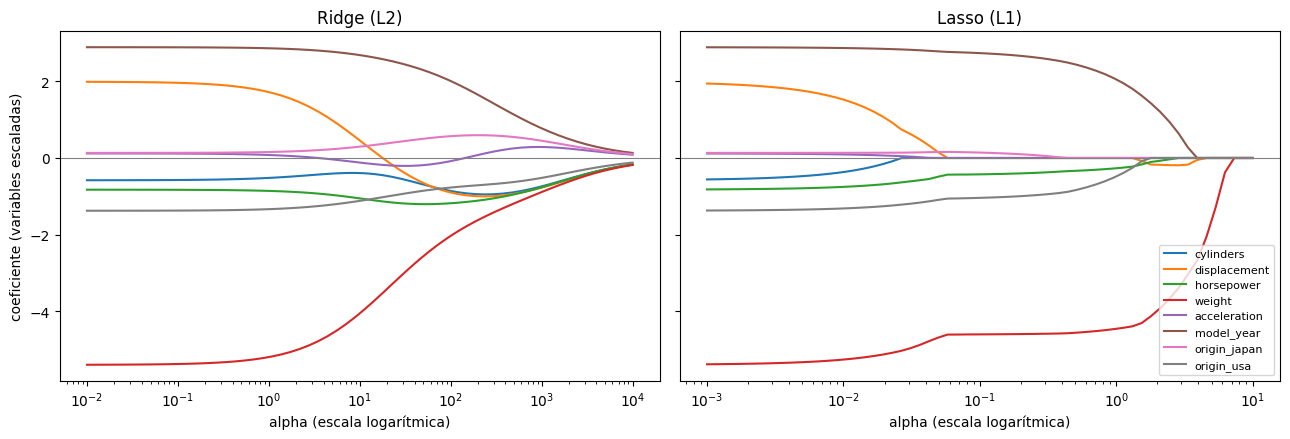

In [8]:
escalador = StandardScaler().fit(X_train)
Xs = escalador.transform(X_train)
alphas_r = np.logspace(-2, 4, 60)
alphas_l = np.logspace(-3, 1, 60)
coef_r = [Ridge(alpha=a).fit(Xs, y_train).coef_ for a in alphas_r]
coef_l = [Lasso(alpha=a, max_iter=50000).fit(Xs, y_train).coef_ for a in alphas_l]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, alfas, coefs, titulo in [(axes[0], alphas_r, coef_r, "Ridge (L2)"), (axes[1], alphas_l, coef_l, "Lasso (L1)")]:
    ax.semilogx(alfas, coefs)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set(title=titulo, xlabel="alpha (escala logarítmica)")
axes[0].set_ylabel("coeficiente (variables escaladas)")
axes[1].legend(X.columns, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 7. Elegir alpha con validación cruzada

`RidgeCV` y `LassoCV` prueban una grilla de alphas con validación cruzada **dentro del entrenamiento**
y se quedan con el mejor. Es la misma idea que `GridSearchCV`, pero más eficiente para estos modelos.

In [9]:
grilla = np.logspace(-3, 3, 50)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
ridge_cv = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), RidgeCV(alphas=grilla, cv=kf))
lasso_cv = make_pipeline(PolynomialFeatures(degree=3, include_bias=False), StandardScaler(), LassoCV(alphas=grilla, cv=kf, max_iter=50000))
resultados.append(evaluar("RidgeCV", ridge_cv))
resultados.append(evaluar("LassoCV", lasso_cv))
print(f"alpha elegido por RidgeCV: {ridge_cv[-1].alpha_:.3f}")
print(f"alpha elegido por LassoCV: {lasso_cv[-1].alpha_:.3f}")
print("Coeficientes distintos de cero con LassoCV:", np.sum(lasso_cv[-1].coef_ != 0), "de", lasso_cv[-1].coef_.size)
display(pd.DataFrame(resultados).round(3))

alpha elegido por RidgeCV: 8.286
alpha elegido por LassoCV: 0.004
Coeficientes distintos de cero con LassoCV: 30 de 164


,Modelo,R² entrenamiento,R² prueba,MAE prueba
0,Lineal (8 variables),0.829,0.792,2.462
1,Lineal polinómica (164 variables),0.959,-17969.689,173.160
2,"Ridge, alpha = 10",0.891,0.854,2.015
3,"Lasso, alpha = 0.05",0.882,0.859,1.981
4,RidgeCV,0.892,0.855,2.010
5,LassoCV,0.905,0.859,1.921


**Lectura:** los modelos regularizados recuperan el desempeño en prueba sin tirar las variables nuevas a mano.
Lasso además entrega un modelo más chico, con menos variables activas.

## 8. ¿Qué variables elige Lasso?

Con las 8 variables originales y el alpha elegido por validación cruzada, comparamos los coeficientes de Lasso con los de la regresión lineal.

In [10]:
lasso_simple = make_pipeline(StandardScaler(), LassoCV(cv=kf, max_iter=50000)).fit(X_train, y_train)
pd.DataFrame({"Coeficiente Lasso": lasso_simple[-1].coef_,
              "Coeficiente lineal": make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)[-1].coef_},
             index=X.columns).round(3)

,Coeficiente Lasso,Coeficiente lineal
cylinders,-0.332,-0.581
displacement,1.448,1.990
horsepower,-0.742,-0.826
weight,-5.234,-5.394
acceleration,0.088,0.119
model_year,2.864,2.889
origin_japan,0.135,0.133
origin_usa,-1.306,-1.376


**Lectura:** con pocas variables y bastantes datos, Lasso casi no interviene: encoge apenas los coeficientes y no anula ninguno.
La selección aparece cuando sobran variables, como en el punto 4. El gráfico del punto 6 muestra el orden en que se
apagarían al subir alpha: primero `cylinders` y `acceleration`; al final, `model_year` y `weight`.

**La idea central:** la regularización agrega un costo por la complejidad del modelo. **Ridge** encoge todos
los coeficientes y estabiliza el modelo cuando hay muchas variables o variables correlacionadas; **Lasso**
además selecciona variables. En ambos casos, `alpha` es un hiperparámetro y se elige con validación cruzada.

## Para practicar

1. Repitan el punto 7 con `PolynomialFeatures(degree=2)`. ¿Sigue haciendo falta regularizar?
2. Prueben `ElasticNetCV` con `l1_ratio=[0.2, 0.5, 0.8]`. ¿Qué combinación elige?
3. Continúen con la **guía de experimentación de regresión**, consigna 1, punto e (California Housing con Ridge y Lasso).

**Fuentes:** [Auto MPG, UCI (1993), CC BY 4.0](https://doi.org/10.24432/C5859H)
· [Linear models, scikit-learn](https://scikit-learn.org/stable/modules/linear_model.html)
· James et al. (2021), *An Introduction to Statistical Learning*, cap. 6